# DSCI 552 Homework 4

**Course:** DSCI 552, Machine Learning for Data Science (Fall 2026)

**Assignment:** Homework 4 (HW 4 starts from mid of this notebook)

**Name:** Zhonghao Yang

**Github Username:** ZhonghaoYang-EDDIE

**Date:** October 19, 2026

**AI Assistance Disclosure:** AI assistance was used (Claude.ai from Anthropic) in this assignment, mainly with code and syntax questions, and LaTeX formatting for the last two questions.

In [45]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



DATA_DIR = os.path.join(os.getcwd(), 'AReM')
print(DATA_DIR, os.path.isdir(DATA_DIR))

ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying',
              'sitting', 'standing', 'walking']
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13',
          'var_rss13', 'avg_rss23', 'var_rss23']

c:\Users\15699\OneDrive\桌面\USC Viterbi ADS\DSCI 552\hw 4\AReM True


### Data Cleaning Notes

After inspecting all 88 files, I found that 4 of them had minor formatting problems:

- `bending2/dataset4.csv`: space-delimited instead of comma-delimited, with trailing spaces.
- `cycling/dataset9.csv` and `cycling/dataset14.csv`: the last row ends with an extra comma.
- `sitting/dataset8.csv`: only 479 rows; the row at timestamp 13500 is missing.

I fixed the first three files manually in VS Code (replacing the spaces with commas in `dataset4.csv`, and deleting the extra comma in the two `cycling` files). 

I did not modify `sitting/dataset8.csv` since a single missing row out of 480 has a small effect on summary statistics such as min, max, and mean, so I used its 479 rows as they are.

In [46]:
## 1(b)
def read_instance(path):
    #Read one AReM file and return its 6 time series.
    return pd.read_csv(path, comment='#', header=None, names=['time'] + SERIES)[SERIES]

In [47]:
records = []
for act in ACTIVITIES:
    n_files = len(glob.glob(os.path.join(DATA_DIR, act, 'dataset*.csv')))
    n_test = 2 if act.startswith('bending') else 3   # split rule in 1(b): test set: first 2 files for bending, first 3 for others
    for idx in range(1, n_files + 1):
        path = os.path.join(DATA_DIR, act, f'dataset{idx}.csv')
        records.append({'activity': act, 'dataset': idx,
                        'split': 'test' if idx <= n_test else 'train',
                        'data': read_instance(path)})

meta = pd.DataFrame(records)[['activity', 'dataset', 'split']]
print(len(records), 'instances')
print(pd.crosstab(meta['activity'], meta['split']))
print(pd.Series([r['data'].shape for r in records]).value_counts())

88 instances
split     test  train
activity             
bending1     2      5
bending2     2      4
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12
(480, 6)    87
(479, 6)     1
Name: count, dtype: int64


## 1(c)i. Common Time-Domain Features

Based on my reasearch commonly used time-domain features include:

- **Location:** minimum, maximum, mean, median, first and last value.
- **Spread:** standard deviation, variance, range (max - min), first quartile (Q1), third quartile (Q3), interquartile range (IQR), mean absolute deviation.
- **Shape of the distribution:** skewness, kurtosis.
- **Energy / magnitude:** root mean square (RMS), signal energy (sum of squares).
- **Dynamics over time:** autocorrelation, linear trend (slope), zero-crossing rate or mean-crossing rate, number of peaks, mean absolute change between consecutive values.

In this assignment I use the seven features suggested in the problem: minimum, maximum, mean, median, standard deviation, first quartile and third quartile.

## 1(c)ii.


In [48]:
def extract_features(df):
    stats = pd.DataFrame({'min': df.min(), 'max': df.max(), 'mean': df.mean(),
                          'median': df.median(), 'std': df.std(),
                          '1st quart': df.quantile(0.25), '3rd quart': df.quantile(0.75)})
    return pd.Series({f'{stat}{i}': stats.loc[s, stat]
                      for i, s in enumerate(SERIES, start=1) for stat in stats.columns})


features = pd.DataFrame([extract_features(r['data']) for r in records])
features.index = range(1, len(records) + 1)
features.index.name = 'Instance'

print(features.shape)
features.head()

(88, 42)


,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,...,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 1(c)iii. Standard Deviation and 90% Bootstrap Confidence Intervals

For each of the 42 features, I estimate its standard deviation across the 88 files. To quantify the uncertainty of each estimate, I build a 90% bootstrap confidence interval (percentile method):

1. Draw 88 instances with replacement from the original 88 instances.
2. Compute the standard deviation of every feature on this resample.
3. Repeat 1000 times, giving 1000 bootstrap standard deviations per feature.
4. Take the 5th and 95th percentiles of these 1000 values as the lower and upper bounds of the interval.

In [49]:
B = 1000                               # number of bootstrap resamples
rng = np.random.default_rng(0)         # fixed seed for reproducibility
X = features.values                    # 88 x 42 array

# Each resample draws 88 instances with replacement, then recomputes the std of every feature
boot_std = np.array([X[rng.integers(0, len(X), len(X))].std(axis=0, ddof=1)
                     for _ in range(B)])

lower, upper = np.percentile(boot_std, [5, 95], axis=0)   # 90% percentile interval
std_ci = pd.DataFrame({'std': features.std(), 'CI lower (5%)': lower, 'CI upper (95%)': upper})
std_ci.round(3)

,std,CI lower (5%),CI upper (95%)
min1,9.570,8.295,10.819
max1,4.394,3.335,5.273
mean1,5.336,4.706,5.851
median1,5.440,4.841,6.000
std1,1.772,1.573,1.957
1st quart1,6.154,5.615,6.641
3rd quart1,5.139,4.336,5.841
min2,0.000,0.000,0.000
max2,5.063,4.626,5.375
mean2,1.574,1.394,1.702


## 1(c)iv. Selecting the Three Most Important Features


**Selected features: mean, standard deviation and maximum.**

- The mean describes the average signal level, which differs between activities.
- The standard deviation describes how much the signal fluctuates, which also differs between activities and is not redundant with the mean.
- The maximum captures extreme values and complements the other two.
- I do not select the minimum: `min2` and `min4` have a standard deviation of 0 in 1(c)iii (the minimum is 0 for every instance), so they carry no information.

## 2. ISLR 3.7.4

**(a)** The cubic regression should have the lower (or equal) training RSS. The linear model is a special case of the cubic model (set the X² and X³ coefficients to zero), so least squares can always fit the training data at least as well with the cubic model. Even when the true relationship is linear, the extra terms let the cubic model fit some of the random noise, which lowers its training RSS.

**(b)** The linear regression should have the lower test RSS. Since the true relationship is linear, the linear model has no bias and a lower variance. The cubic model overfits: it fits the noise in the training data, and that noise does not carry over to the test data, so its test RSS is higher on average.

**(c)** The cubic regression should have the lower training RSS. The linear model is a special case of the cubic model, so the cubic model can always fit the training data at least as well. This holds no matter how far the true relationship is from linear, and since the true relationship is not linear, the cubic model can also follow the curve more closely.

**(d)** There is not enough information to tell; it depends on how far the true relationship is from linear. If it is close to linear (or the noise is large), the lower variance of the linear model dominates and the linear model has the lower test RSS. If it is far from linear, for example close to cubic, the bias of the linear model is large and the cubic model has the lower test RSS. This is the bias-variance trade-off.

---




# HOMEWORK 4 STARTS HERE

---

> Everything above this cell is carried over from Homework 3 (Time Series Classification Part 1: data loading and feature extraction, and the ISLR 3.7.4 answer). The feature creation code is kept because it is reused below.
>
> **The Homework 4 solutions start with Problem 2(a)i.**

---

## 2(a)i. Scatter Plots of the Selected Features

Using only the training set, I plot the selected features (mean, standard deviation and maximum) of time series 1, 2 and 6, colored by bending vs. other activities.

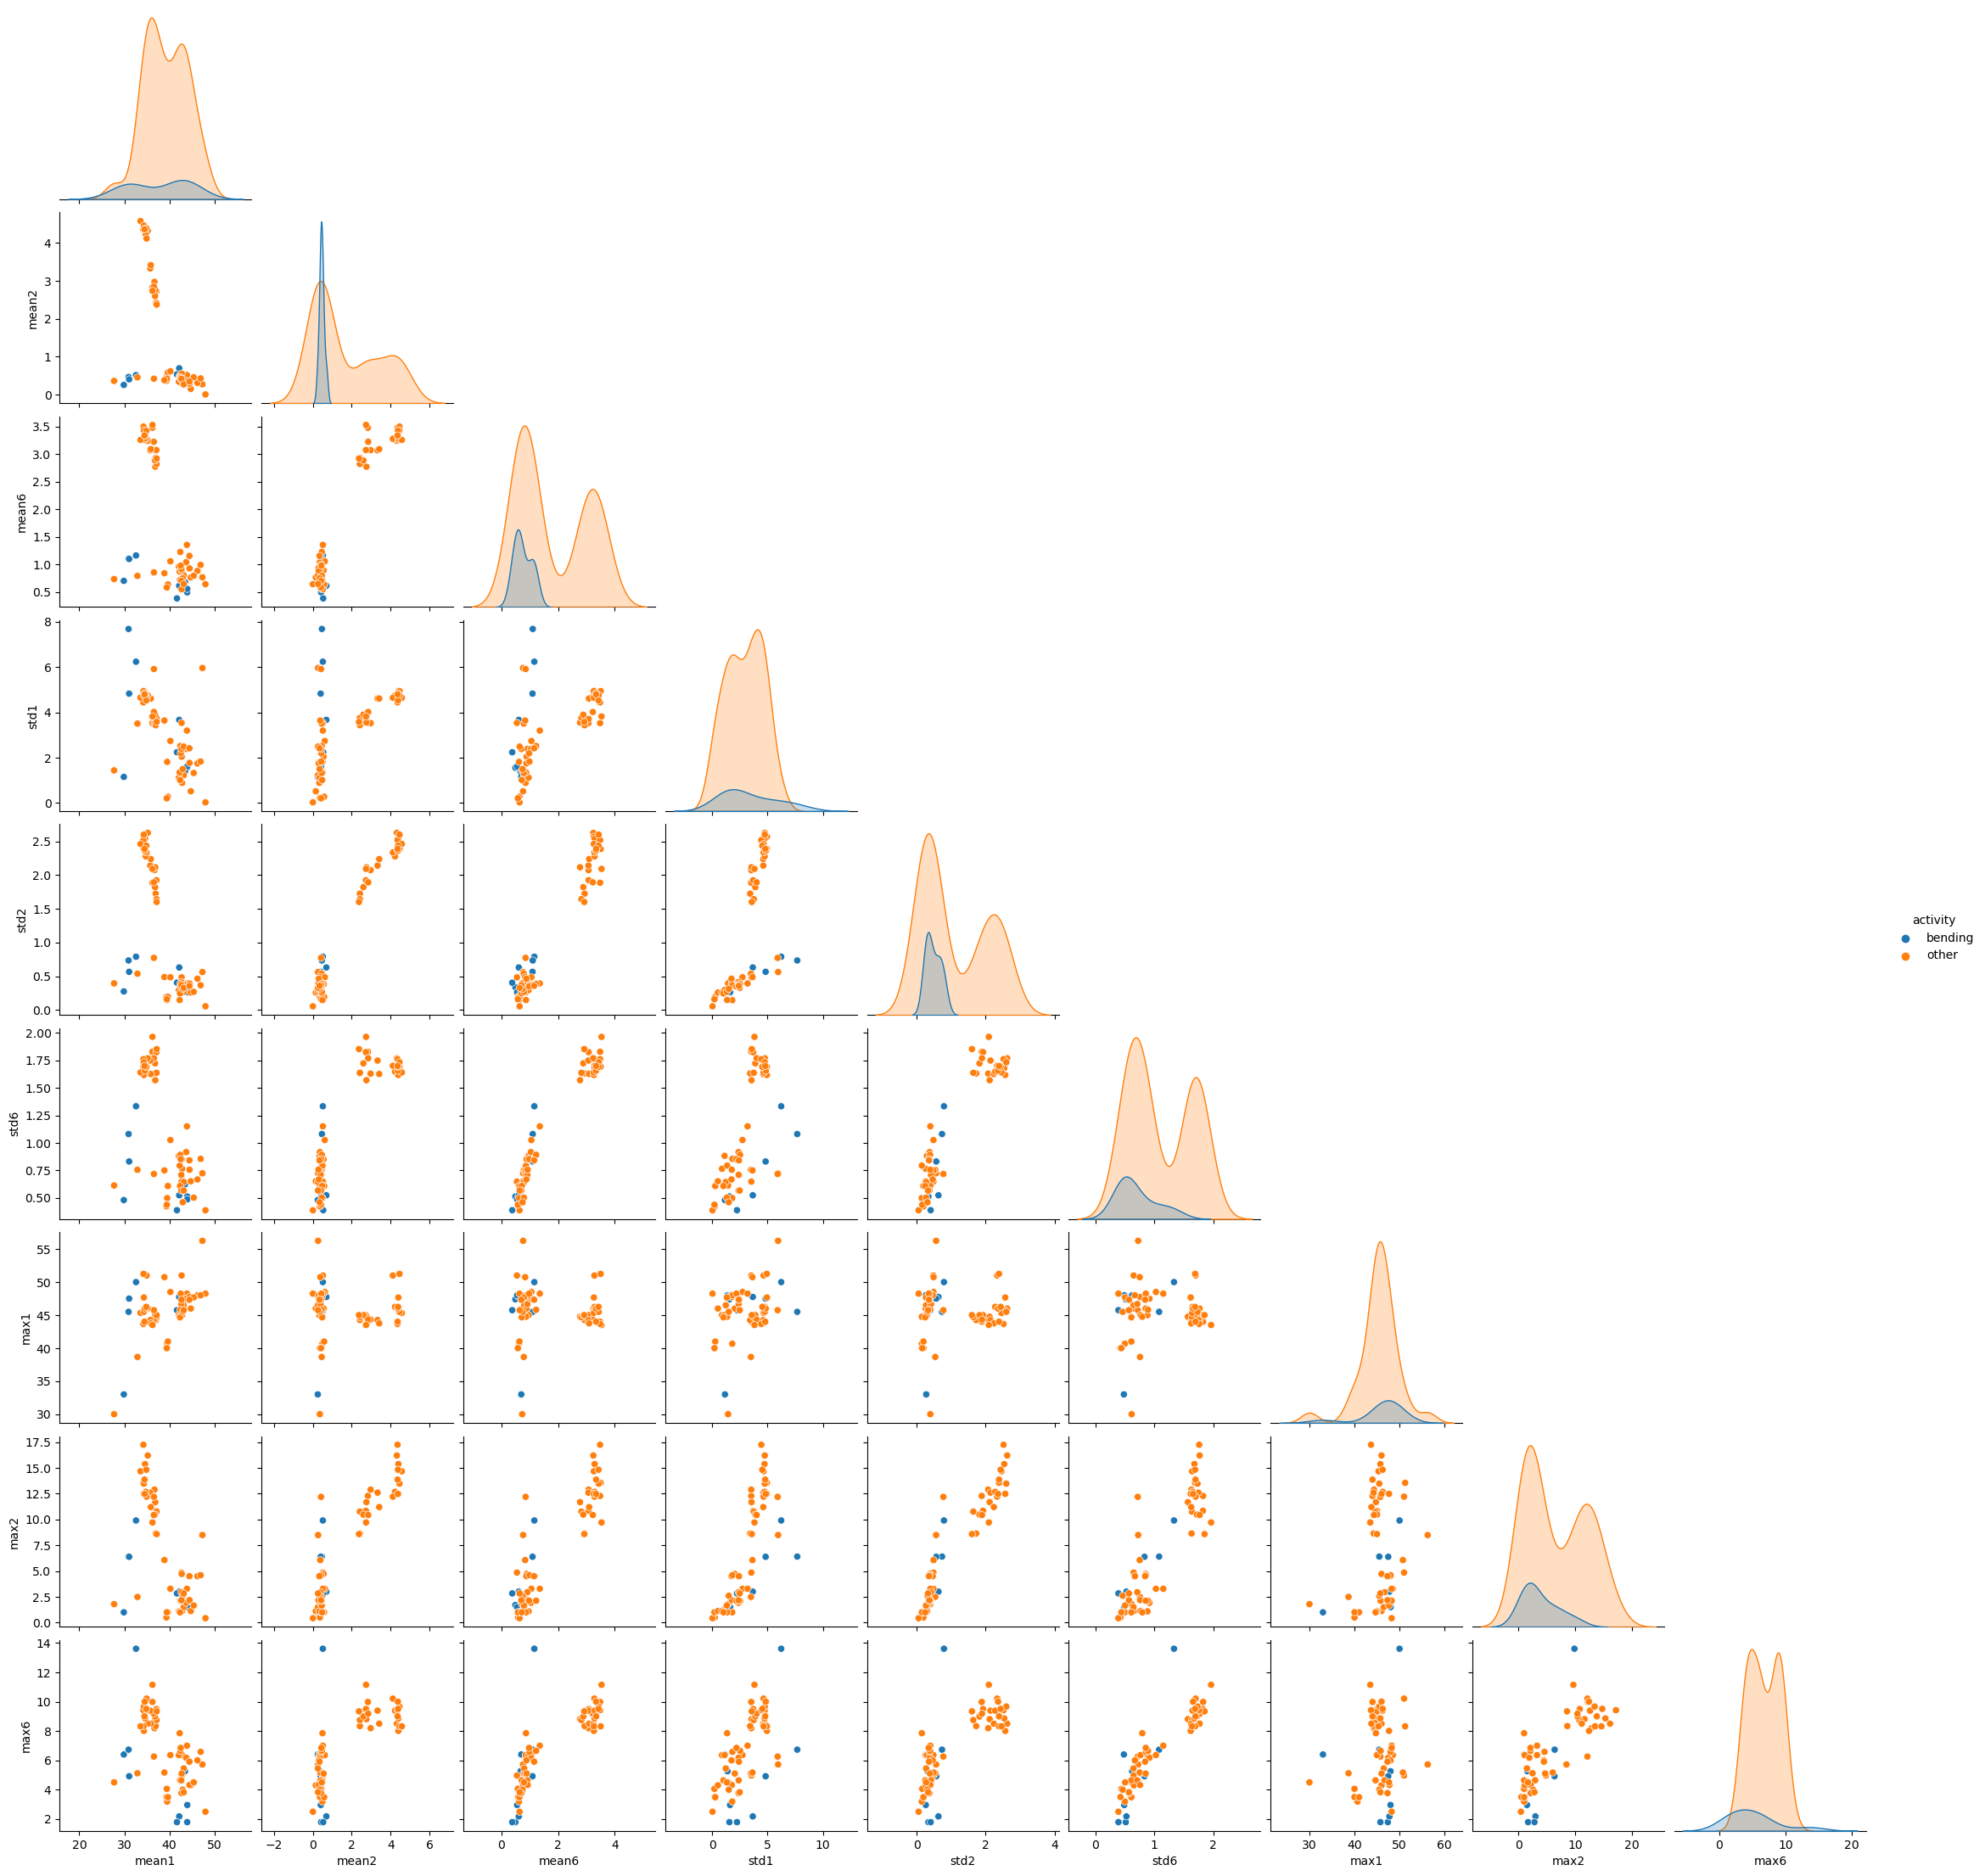

In [50]:
is_train = pd.Series([r['split'] == 'train' for r in records], index=features.index)
activity = pd.Series(['bending' if r['activity'].startswith('bending') else 'other'
                      for r in records], index=features.index)

# The selected features (mean, std, max) of time series 1, 2 and 6
cols = [f'{s}{i}' for s in ('mean', 'std', 'max') for i in (1, 2, 6)]
data = features.loc[is_train, cols].assign(activity=activity[is_train])

sns.pairplot(data, hue='activity', corner=True)
plt.show()

The training set contains 9 bending and 60 other instances. The bending instances mostly lie in the region where the mean and standard deviation of the variance series (time series 2 and 6) are small, but they overlap with other activities in this region, so no pair of features separates the two classes clearly. The classes are also imbalanced.

## 2(a)ii. Splitting Each Time Series into Two Parts

In [51]:
def extract_features_l(df, l):
    """Split each series into l equal parts; return the 7 features of every part as one flat row."""
    row = {}
    for k, idx in enumerate(np.array_split(np.arange(len(df)), l), start=1):
        part = df.iloc[idx]
        stats = pd.DataFrame({'min': part.min(), 'max': part.max(), 'mean': part.mean(),
                              'median': part.median(), 'std': part.std(),
                              '1st quart': part.quantile(0.25), '3rd quart': part.quantile(0.75)})
        for i, s in enumerate(SERIES, start=1):
            for stat in stats.columns:
                row[f'{stat}{i}_{k}'] = stats.loc[s, stat]
    return pd.Series(row)

features2 = pd.DataFrame([extract_features_l(r['data'], 2) for r in records], index=features.index)
print(features2.shape)

(88, 84)


Part 1


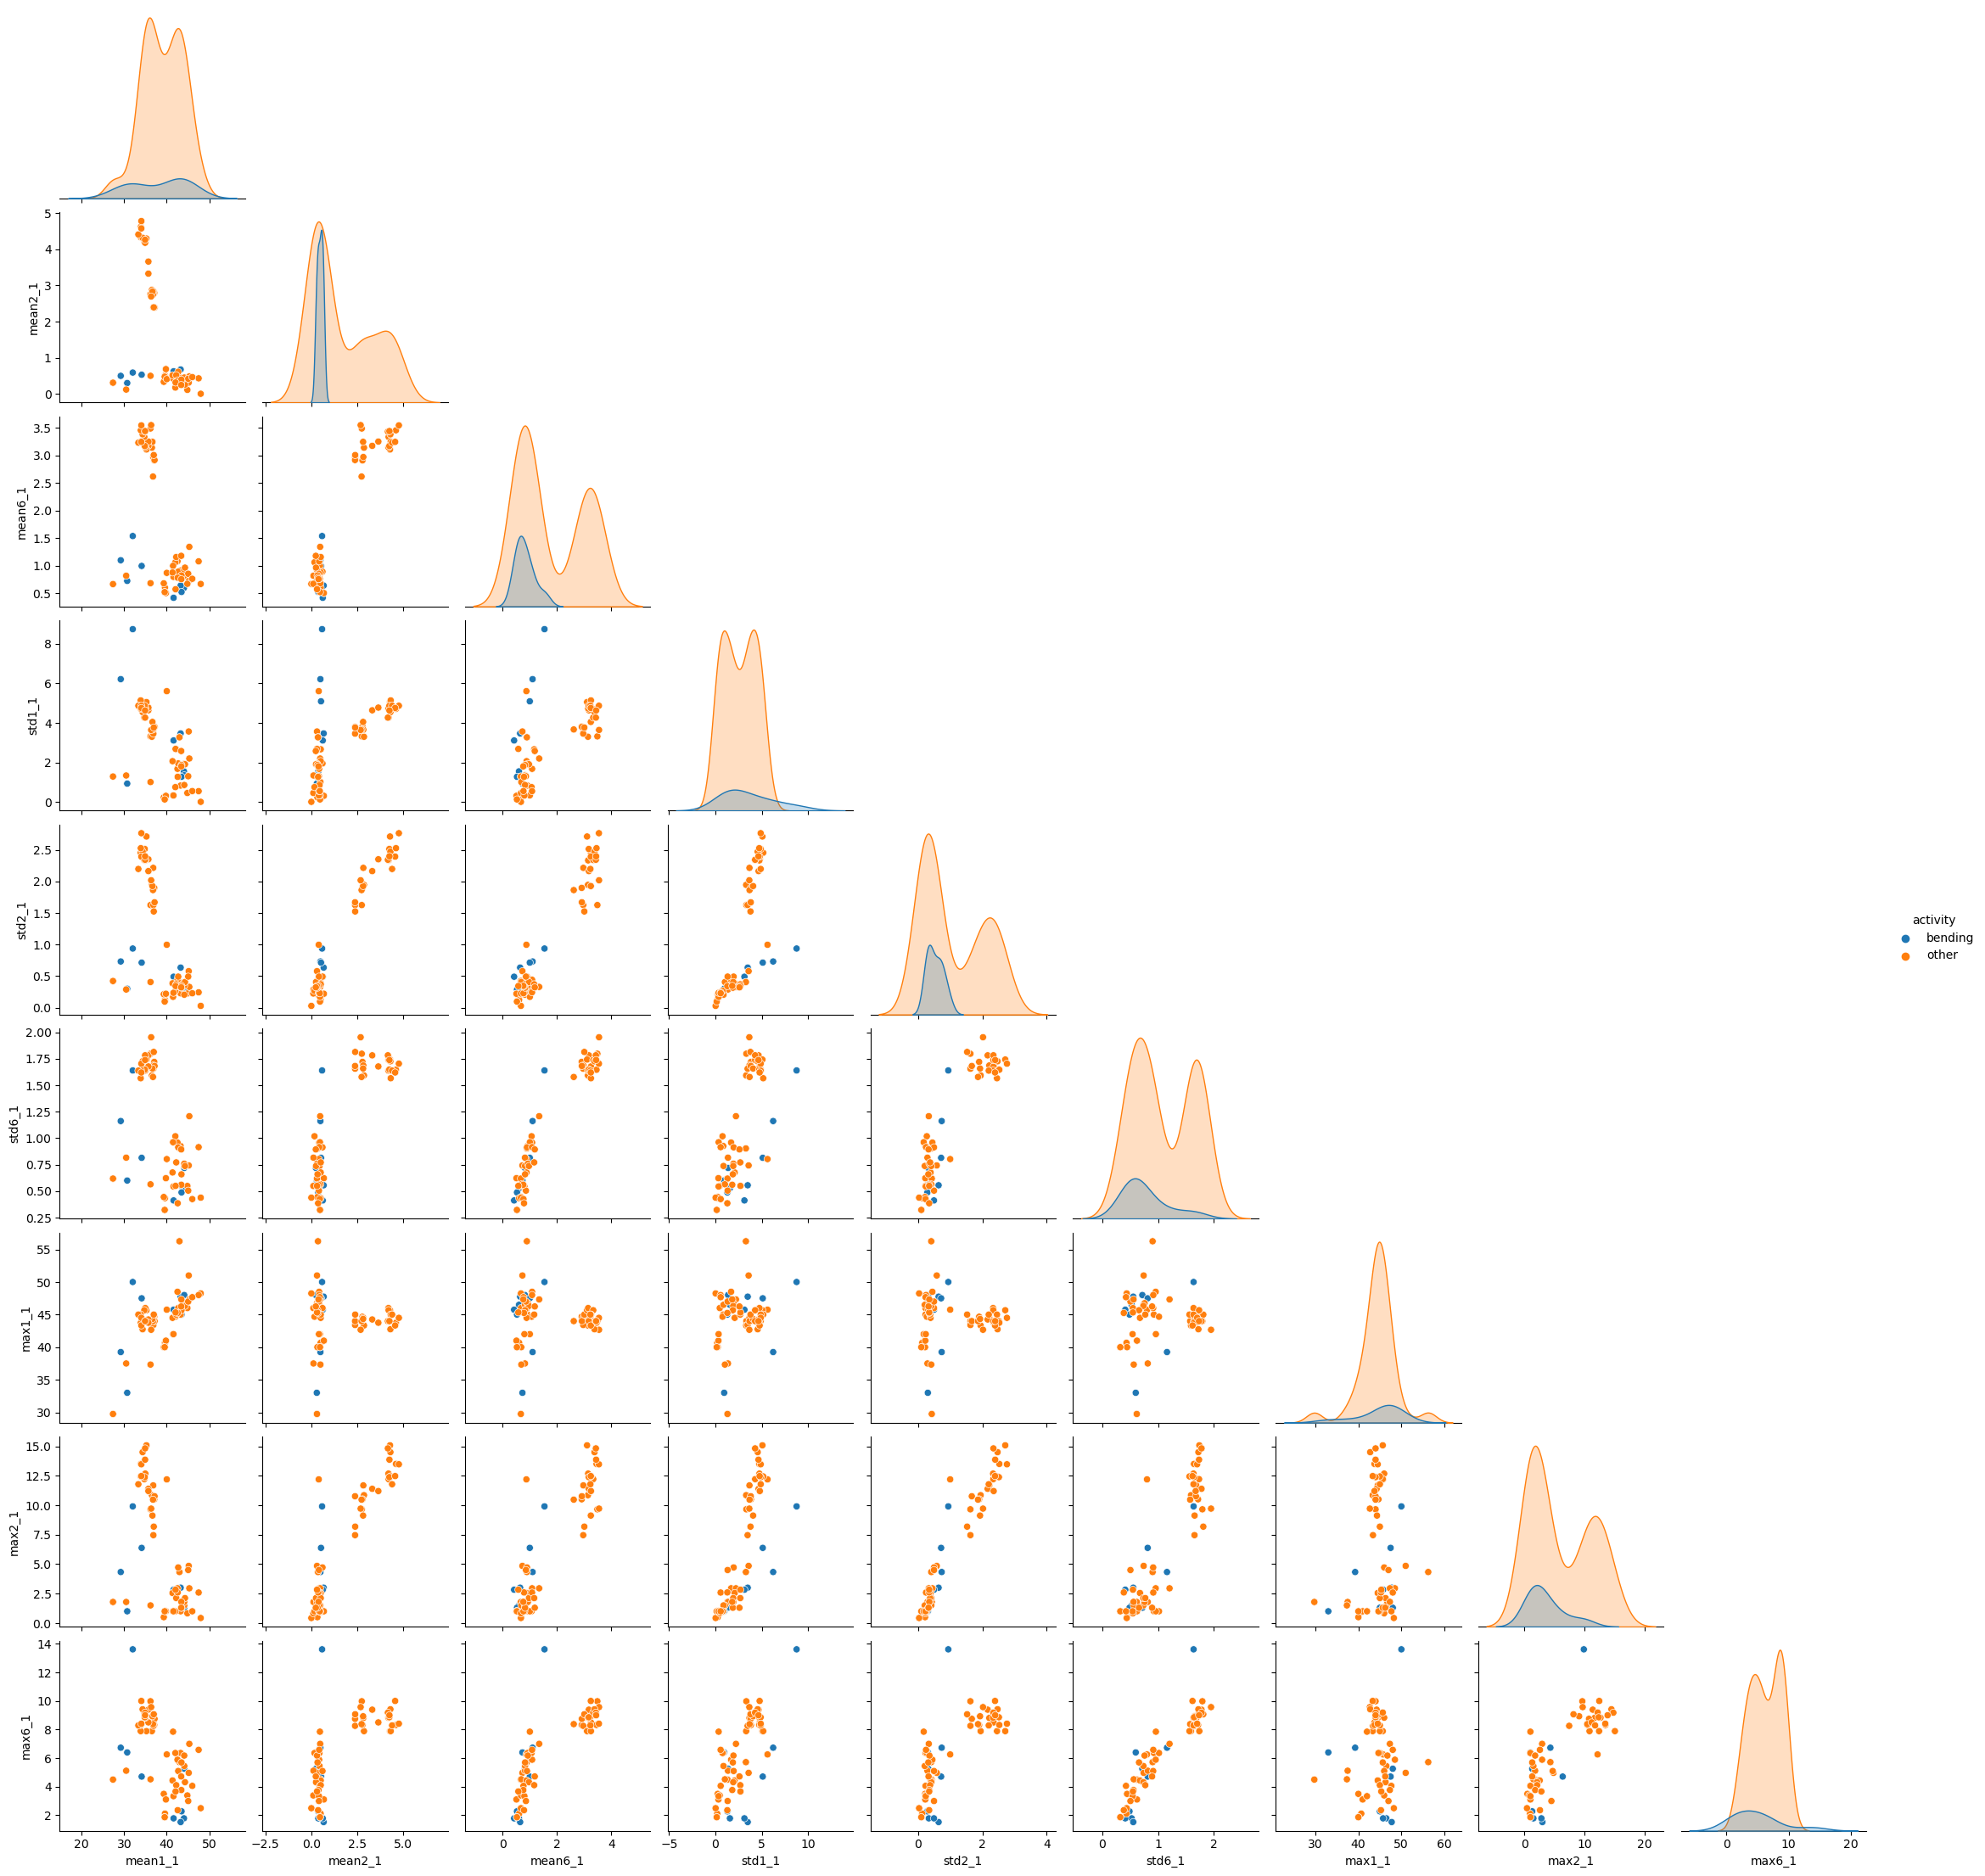

Part 2


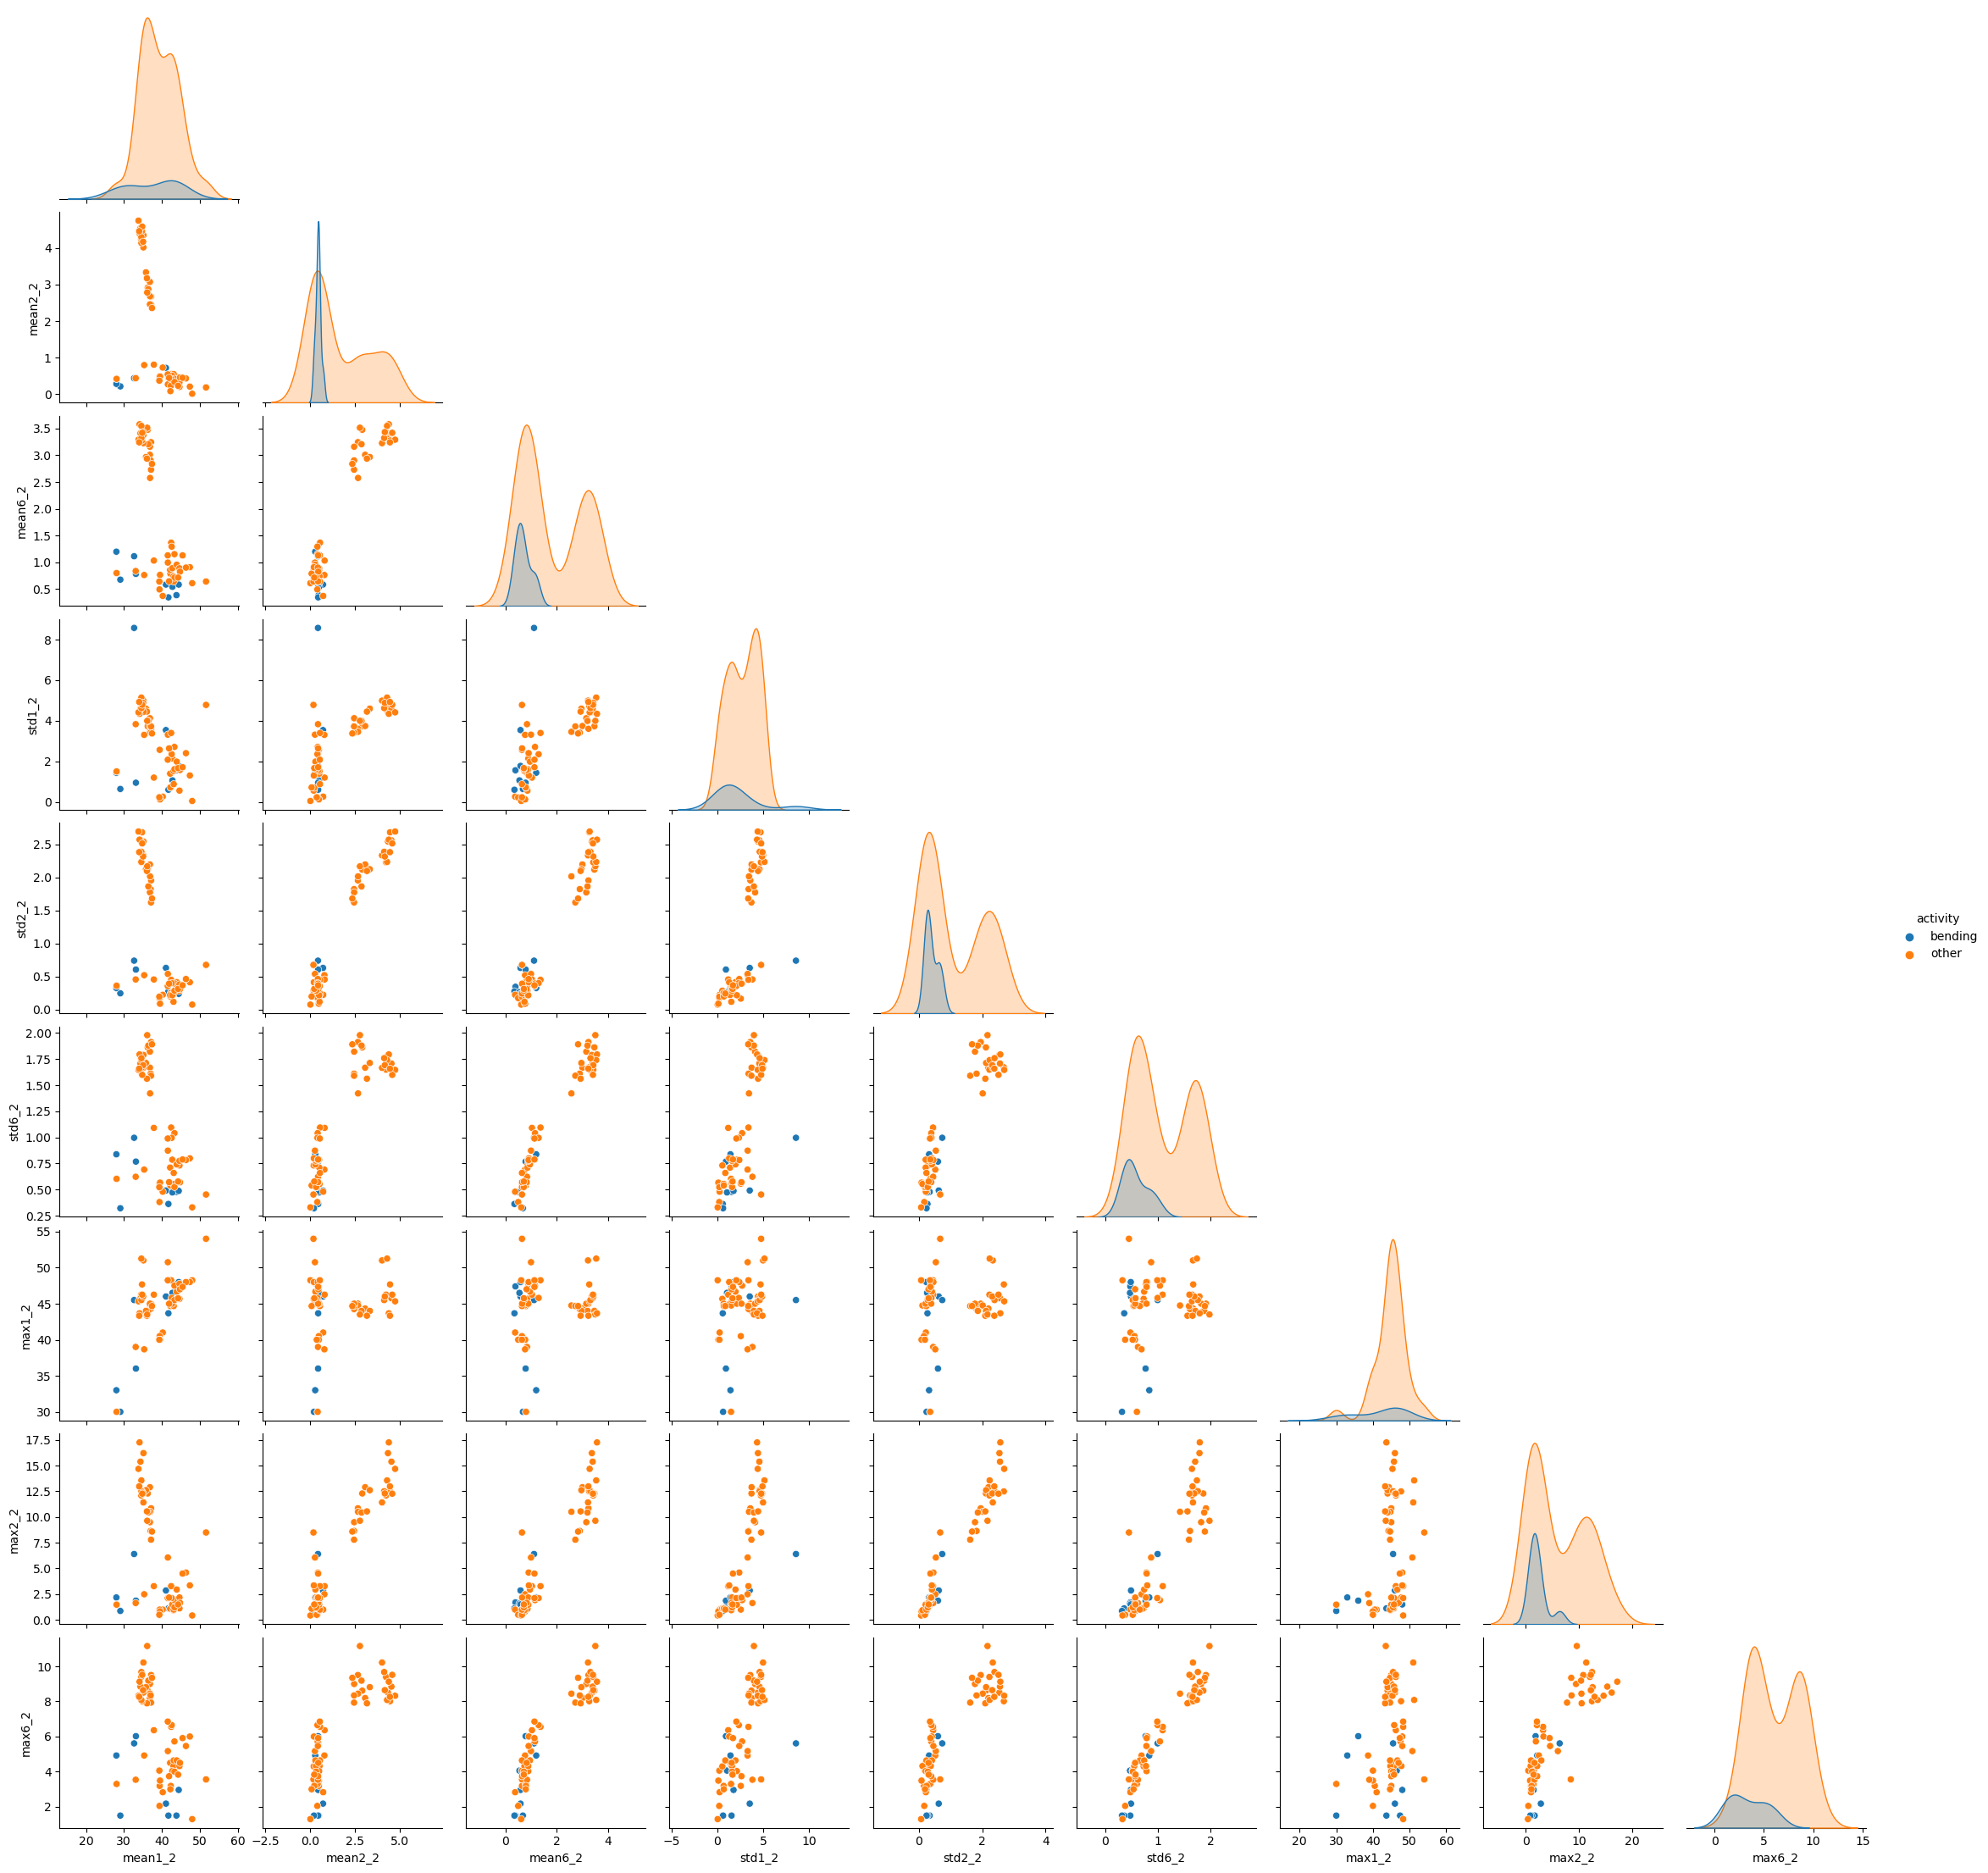

In [52]:
for k in (1, 2):
    cols = [f'{s}{i}_{k}' for s in ('mean', 'std', 'max') for i in (1, 2, 6)]
    data = features2.loc[is_train, cols].assign(activity=activity[is_train])
    print(f'Part {k}')
    sns.pairplot(data, hue='activity', corner=True)
    plt.show()

I do not see a considerable difference. The plots of both parts look very similar to the plots in 2(a)i: the clusters have the same shape, and the bending instances still overlap with the other activities. A likely reason is that the signal of each activity is fairly stationary over the 120 seconds, so the statistics of each half are close to those of the whole series.

## 2(a)iii. Logistic Regression with Recursive Feature Elimination

For each l in {1, ..., 20}, every time series is split into l parts, and the mean, standard deviation and maximum (selected in 1(c)iv) of every part of every series are used as features, giving 18l features per instance. For each l, recursive feature elimination (RFE) with 5-fold cross-validation chooses the number of features p. The pair (l, p) with the best cross-validation accuracy is selected.

**Right vs. wrong way to cross-validate.** The wrong way is to run feature selection on the whole training set first and then cross-validate the model with the selected features: the validation folds were already used to choose the features, so the cross-validation accuracy is optimistically biased. The right way is to perform the feature selection (and the standardization) inside each fold, using only the training part of that fold, and to evaluate on the held-out part. `RFECV` with a pipeline does exactly this.

Because only 9 of the 69 training instances are bending, I use stratified folds so that every fold contains bending instances.

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train = (activity[is_train] == 'bending').astype(int).values   # 1 = bending, 0 = other
STATS = ('mean', 'std', 'max')                                   # features selected in 1(c)iv

def build_X(l):
    """Training-set features when every series is split into l parts."""
    F = pd.DataFrame([extract_features_l(r['data'], l) for r in records], index=features.index)
    cols = [f'{s}{i}_{k}' for k in range(1, l + 1) for i in range(1, 7) for s in STATS]
    return F.loc[is_train, cols]

print(build_X(1).shape, build_X(20).shape)

(69, 18) (69, 360)


In [54]:


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
# C=1e9 means (practically) no regularization
model = make_pipeline(StandardScaler(), LogisticRegression(C=1e9, max_iter=1000))

results = []
for l in range(1, 21):
    X = build_X(l)
    rfecv = RFECV(model, step=1, cv=cv, scoring='accuracy', n_jobs=-1,
                  importance_getter='named_steps.logisticregression.coef_')
    rfecv.fit(X.values, y_train)
    acc = rfecv.cv_results_['mean_test_score']        # CV accuracy for p = 1, ..., 18l
    p = int(np.argmax(acc)) + 1                       # best p for this l
    results.append({'l': l, 'best p': p, 'CV accuracy': acc[p - 1], 'n features': X.shape[1]})

cv_results = pd.DataFrame(results)
cv_results.round(3)

,l,best p,CV accuracy,n features
0,1,2,0.957,18
1,2,6,0.957,36
2,3,11,0.956,54
3,4,41,0.942,72
4,5,1,0.942,90
5,6,27,0.956,108
6,7,3,0.957,126
7,8,22,0.942,144
8,9,14,0.942,162
9,10,10,0.970,180


In [55]:
best = cv_results.loc[cv_results['CV accuracy'].idxmax()]
best_l, best_p = int(best['l']), int(best['best p'])
print(f"Best (l, p) = ({best_l}, {best_p}), CV accuracy = {best['CV accuracy']:.3f}")

Best (l, p) = (17, 10), CV accuracy = 0.985


The best pair is (l, p) = (17, 10): splitting every time series into 17 parts (306 features) and keeping 10 of them by RFE gives the highest 5-fold cross-validation accuracy, 0.985. All other pairs are between 0.941 and 0.970, and the baseline of predicting "other" for every instance is 60/69 = 0.87.

## 2(a)iv. Training Performance, Coefficients and p-values

In [56]:

import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

X = build_X(best_l)

# Final feature selection: RFE on the whole training set, keeping best_p features
rfe = RFE(model, n_features_to_select=best_p,
          importance_getter='named_steps.logisticregression.coef_')
rfe.fit(X.values, y_train)
selected = list(X.columns[rfe.support_])
print(selected)

# Refit with statsmodels (on standardized features) to get coefficients and p-values
scaler = StandardScaler().fit(X[selected])
X_sel = sm.add_constant(pd.DataFrame(scaler.transform(X[selected]),
                                     index=X.index, columns=selected))
logit = sm.Logit(y_train, X_sel).fit(disp=0)
logit.summary2().tables[1].round(3)

['max5_1', 'std4_2', 'mean5_3', 'mean5_5', 'max5_5', 'max6_6', 'std3_8', 'max1_10', 'std6_13', 'std5_16']


c:\Users\15699\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\15699\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-31.673,237522.738,-0.0,1.0,-465567.684,465504.339
max5_1,12.400,337216.221,0.0,1.0,-660919.248,660944.049
std4_2,11.174,306727.720,0.0,1.0,-601164.111,601186.458
mean5_3,10.416,330217.145,0.0,1.0,-647203.295,647224.126
mean5_5,-5.475,278563.128,-0.0,1.0,-545979.173,545968.222
max5_5,4.560,374249.140,0.0,1.0,-733510.275,733519.395
max6_6,-8.650,346930.694,-0.0,1.0,-679980.315,679963.014
std3_8,0.216,71002.667,0.0,1.0,-139162.454,139162.887
max1_10,-12.365,238002.575,-0.0,1.0,-466488.841,466464.110
std6_13,-7.283,395102.268,-0.0,1.0,-774393.499,774378.933


[[60  0]
 [ 0  9]]


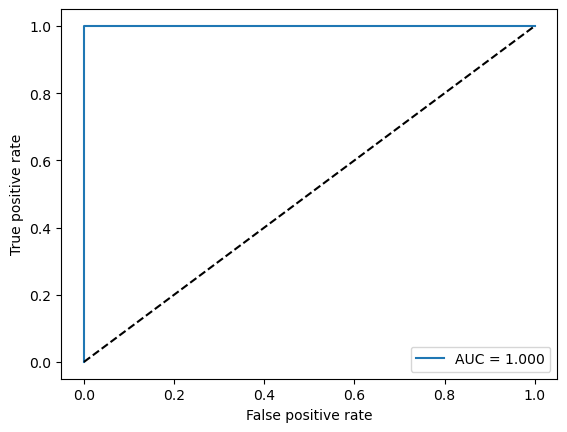

In [57]:
prob = logit.predict(X_sel)                  # predicted probability of bending
pred = (prob > 0.5).astype(int)
print(confusion_matrix(y_train, pred))       # rows: true (other, bending); columns: predicted

fpr, tpr, _ = roc_curve(y_train, prob)
auc = roc_auc_score(y_train, prob)
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()

**Results for 2(a)iv.** With (l, p) = (17, 10), RFE selects the features `max5_1`, `std4_2`, `mean5_3`, `mean5_5`, `max5_5`, `max6_6`, `std3_8`, `max1_10`, `std6_13` and `std5_16` (named statistic, time series, part). The fitted coefficients (on standardized features) and their p-values are shown in the table above.

On the training set the confusion matrix is [[60, 0], [0, 9]] and the AUC is 1.0, so all 69 training instances are classified correctly.

All p-values are 1.0 and the standard errors are huge (about 10^5), and statsmodels warns about perfect separation and non-convergence. The reason is that the two classes are perfectly separable with these features: the maximum likelihood estimate does not exist (the coefficients would grow without bound), so the optimizer simply stops at its iteration limit. The coefficients and p-values are therefore not meaningful here.

## 2(a)v. Test Set Performance

In [58]:
from sklearn.metrics import accuracy_score

In [59]:
is_test = ~is_train

# Test features: split every test series into the same best_l parts and keep the selected features
F_test = pd.DataFrame([extract_features_l(r['data'], best_l) for r in records],
                      index=features.index).loc[is_test, selected]
y_test = (activity[is_test] == 'bending').astype(int).values

# Standardize with the scaler fitted on the training set (never refit it on the test data)
X_test = sm.add_constant(pd.DataFrame(scaler.transform(F_test),
                                      index=F_test.index, columns=selected))

prob_test = logit.predict(X_test)
pred_test = (prob_test > 0.5).astype(int)
print('Test accuracy:', accuracy_score(y_test, pred_test))
print(confusion_matrix(y_test, pred_test))
print('Test AUC:', roc_auc_score(y_test, prob_test))

Test accuracy: 0.9473684210526315
[[15  0]
 [ 1  3]]
Test AUC: 0.8166666666666667



The test set contains 19 instances (4 bending, 15 other). Each test time series is split into the same l = 17 parts, the same 10 features are extracted, and they are standardized with the scaler fitted on the training set.

The test accuracy is 0.947 (confusion matrix [[15, 0], [1, 3]]): all 15 other instances are correct, and 3 of the 4 bending instances are found. This is slightly lower than the cross-validation accuracy of 0.985, which is expected because that value is the maximum over many (l, p) pairs and is therefore optimistic, and the model fits the training data perfectly (overfitting). The test AUC is 0.817, lower than the training AUC of 1.0: the missed bending instance is ranked above only 4 of the 15 other instances, and with only 4 bending instances in the test set a single instance changes the AUC a lot. The test accuracy is much higher than the baseline of 15/19 = 0.789 obtained by always predicting "other".

## 2(a)vi. Separability of the Classes

Yes. With the selected features, the two classes are perfectly separable on the training set: the training confusion matrix has no errors and the AUC is 1.0. This causes the instability mentioned in the problem: statsmodels warns about perfect separation and non-convergence, the standard errors are enormous, all p-values are 1.0, and the coefficients depend on where the optimizer stops. This is expected here because 10 features are selected from 306 with only 69 training instances (9 of them bending), which makes it easy to find features that separate the classes.

## 2(a)vii. Class Imbalance and Case-Control Sampling

Yes, the classes are imbalanced: the training set has 9 bending and 60 other instances (13% vs. 87%), and the test set has 4 and 15. Always predicting "other" already gives 87% training accuracy.

To address this, I use case-control sampling: all 9 bending instances (cases) plus 9 randomly drawn other instances (controls) form a balanced training sample, and a logistic regression is fitted on it with the same 10 features. Case-control sampling only biases the intercept, so I correct it by adding log(π / (1 - π)) = log(9/60) to it, where π is the proportion of bending in the original training set; the slopes are kept. The confusion matrices, ROC curves and AUC values on the full training set and on the test set are shown below.

In [60]:
# Case-control sampling: keep all bending (cases) and draw the same number of other (controls)
rng = np.random.default_rng(0)
cases = np.where(y_train == 1)[0]
controls = rng.choice(np.where(y_train == 0)[0], size=len(cases), replace=False)
idx = np.concatenate([cases, controls])

cc = sm.Logit(y_train[idx], X_sel.iloc[idx]).fit(disp=0)

# Adjust the intercept back to the original class proportions (the slopes are unaffected)
beta = cc.params.copy()
beta['const'] += np.log(len(cases) / (len(y_train) - len(cases)))   # log(9/60), since the sample is balanced
beta.round(3)

c:\Users\15699\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\15699\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\15699\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\15699\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\15699\anaconda3

const     -24.026
max5_1     14.314
std4_2      9.836
mean5_3     5.580
mean5_5    -2.470
max5_5      6.839
max6_6     -6.926
std3_8     -1.311
max1_10    -7.949
std6_13   -13.221
std5_16     1.559
dtype: float64

Training accuracy: 1.0
[[60  0]
 [ 0  9]]
Test accuracy: 0.947
[[15  0]
 [ 1  3]]


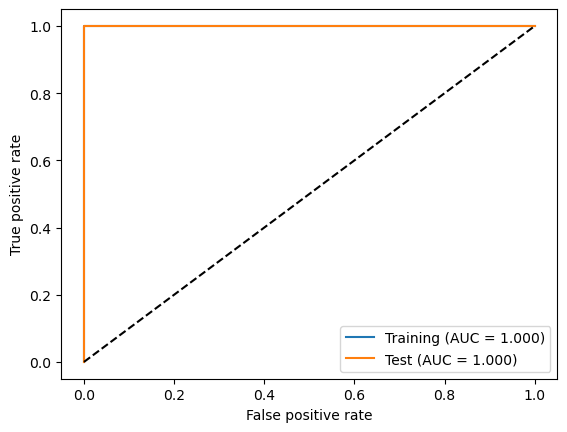

In [61]:
for name, X_m, y_m in [('Training', X_sel, y_train), ('Test', X_test, y_test)]:
    prob = 1 / (1 + np.exp(-(X_m @ beta)))          # logistic function with the adjusted coefficients
    pred = (prob > 0.5).astype(int)
    print(name, 'accuracy:', round(accuracy_score(y_m, pred), 3))
    print(confusion_matrix(y_m, pred))
    fpr, tpr, _ = roc_curve(y_m, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_m, prob):.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()

The training set is classified perfectly (confusion matrix [[60, 0], [0, 9]], AUC = 1.0). On the test set the confusion matrix is [[15, 0], [1, 3]] (accuracy 0.947), the same as without sampling, but the AUC is 1.0: the missed bending instance has a predicted probability of only about 0.03, which is below the 0.5 threshold but still higher than the probability of every other instance, so the ranking is perfect and only the threshold is wrong.

The intercept correction has almost no effect here: the classes are still perfectly separable, so the predicted probabilities are close to 0 or 1, and the confusion matrices are the same without the correction. The results also depend on which 9 other instances are drawn (with other random seeds the test AUC varied noticeably), so a single draw should not be over-interpreted.

## 2(b)i. L1-Penalized Logistic Regression

Instead of selecting features with RFE, I use an L1-penalized logistic regression, which sets the coefficients of unimportant features exactly to zero. For each l in {1, ..., 20}, the same features as in 2(a)iii (mean, standard deviation and maximum of every part of every series, 18l features) are used, and 5-fold stratified cross-validation chooses the penalty parameter C (a small C means a strong penalty). The pair (l, C) with the best cross-validation accuracy is selected.

The features are standardized because the L1 penalty depends on their scale. As in 2(a)iii, the standardization is part of a pipeline, so it is refitted inside every fold using only the training part of that fold. I use the liblinear solver.

In [62]:
from sklearn.model_selection import GridSearchCV

Cs = np.logspace(-3, 2, 20)       # candidate values of C (small C = strong L1 penalty)
pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear'))

results, models = [], {}
for l in range(1, 21):
    X = build_X(l)
    gs = GridSearchCV(pipe, {'logisticregression__C': Cs}, cv=cv, scoring='accuracy', n_jobs=-1)
    gs.fit(X.values, y_train)
    coef = gs.best_estimator_.named_steps['logisticregression'].coef_.ravel()
    results.append({'l': l, 'best C': gs.best_params_['logisticregression__C'],
                    'CV accuracy': gs.best_score_, 'nonzero features': int((coef != 0).sum()),
                    'n features': X.shape[1]})
    models[l] = gs.best_estimator_

l1_results = pd.DataFrame(results)
l1_results.round(3)

,l,best C,CV accuracy,nonzero features,n features
0,1,1.438,0.971,7,18
1,2,0.785,0.943,8,36
2,3,0.234,0.971,3,54
3,4,0.428,0.957,6,72
4,5,0.428,0.942,9,90
5,6,0.234,0.957,3,108
6,7,0.785,0.957,9,126
7,8,0.234,0.927,5,144
8,9,0.234,0.927,6,162
9,10,8.859,0.956,15,180


In [63]:
best = l1_results.loc[l1_results['CV accuracy'].idxmax()]
best_l2 = int(best['l'])
print(f"Best l = {best_l2}, C = {best['best C']:.3f}, CV accuracy = {best['CV accuracy']:.3f}, "
      f"{int(best['nonzero features'])} non-zero features")

# Test-set features: split the test series into the same best_l2 parts
X_tr = build_X(best_l2)
X_te = pd.DataFrame([extract_features_l(r['data'], best_l2) for r in records],
                    index=features.index).loc[is_test, X_tr.columns]

model_l1 = models[best_l2]
pred = model_l1.predict(X_te.values)
prob = model_l1.predict_proba(X_te.values)[:, 1]
print('Test accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print('Test AUC:', roc_auc_score(y_test, prob))

Best l = 12, C = 0.785, CV accuracy = 0.986, 5 non-zero features
Test accuracy: 0.9473684210526315
[[15  0]
 [ 1  3]]
Test AUC: 0.9833333333333334


The best pair is (l, C) = (12, 0.785): splitting every time series into 12 parts (216 features) and a penalty of C = 0.785 gives the highest 5-fold cross-validation accuracy, 0.986, and the L1 penalty keeps only 5 of the 216 features. The pair l = 20 also reaches 0.986; I keep the smaller l, which has fewer features. On the test set, the accuracy is 0.947 (confusion matrix [[15, 0], [1, 3]]) and the AUC is 0.983.

## 2(b)ii. Comparison of L1-Penalized Logistic Regression and RFE

| | RFE (2(a)iii) | L1 penalty (2(b)i) |
|---|---|---|
| Best setting | l = 17, p = 10 | l = 12, C = 0.785 |
| Features used | 10 of 306 | 5 of 216 |
| 5-fold CV accuracy | 0.985 | 0.986 |
| Test accuracy | 0.947 | 0.947 |
| Test AUC | 0.817 | 0.983 |

**Performance.** The two methods perform almost the same: both cross-validation accuracies correspond to one error among the 69 training instances, and both models make the same single error on the test set (a bending instance classified as other). The test AUC of the L1 model is higher, but this comes from the ranking of a single instance in a test set with only 4 bending instances, so I do not consider it a reliable difference. L1 is slightly better in two respects: it reaches the same accuracy with fewer features (5 vs. 10), and its coefficients are stable, because the penalty keeps them finite, whereas the unpenalized model after RFE separates the training classes perfectly, which made its coefficients and p-values meaningless.

**Implementation.** L1 is easier to implement. Feature selection and model fitting happen in one step, and a single `GridSearchCV` call cross-validates C (inside a pipeline, so the standardization is also done correctly inside each fold). With RFE I had to combine `RFECV`, a final refit with statsmodels to obtain p-values, and I still needed care with the instability caused by separable classes.

## 2(c)i. Multinomial L1-Penalized Logistic Regression

All seven activities are classified (bending1 and bending2 are kept as separate classes). As in 2(b)i, for each l in {1, ..., 20} the 18l features are standardized inside a pipeline, and 5-fold stratified cross-validation chooses the penalty parameter C; the l with the best cross-validation accuracy is selected. The multinomial model with an L1 penalty needs the saga solver (liblinear only supports one-vs-rest).

In [64]:
act = pd.Series([r['activity'] for r in records], index=features.index)
y7_train, y7_test = act[is_train].values, act[is_test].values      # labels of the 7 activities

Cs = np.logspace(-2, 1, 8)
pipe = make_pipeline(StandardScaler(),
                     LogisticRegression(penalty='l1', solver='saga', max_iter=3000, tol=1e-3))

results7, models7 = [], {}
for l in range(1, 21):
    X = build_X(l)
    gs = GridSearchCV(pipe, {'logisticregression__C': Cs}, cv=cv, scoring='accuracy', n_jobs=-1)
    gs.fit(X.values, y7_train)
    coef = gs.best_estimator_.named_steps['logisticregression'].coef_      # 7 x n_features
    results7.append({'l': l, 'best C': gs.best_params_['logisticregression__C'],
                     'CV accuracy': gs.best_score_,
                     'nonzero features': int((coef != 0).any(axis=0).sum()),
                     'n features': X.shape[1]})
    models7[l] = gs.best_estimator_

results7 = pd.DataFrame(results7)
results7.round(3)

,l,best C,CV accuracy,nonzero features,n features
0,1,1.389,0.898,14,18
1,2,0.518,0.868,19,36
2,3,1.389,0.840,30,54
3,4,3.728,0.825,57,72
4,5,10.000,0.868,86,90
5,6,10.000,0.853,104,108
6,7,10.000,0.796,123,126
7,8,10.000,0.824,140,144
8,9,1.389,0.809,80,162
9,10,3.728,0.823,144,180


Best l = 1, C = 1.389, CV accuracy = 0.898
Test error: 0.10526315789473684


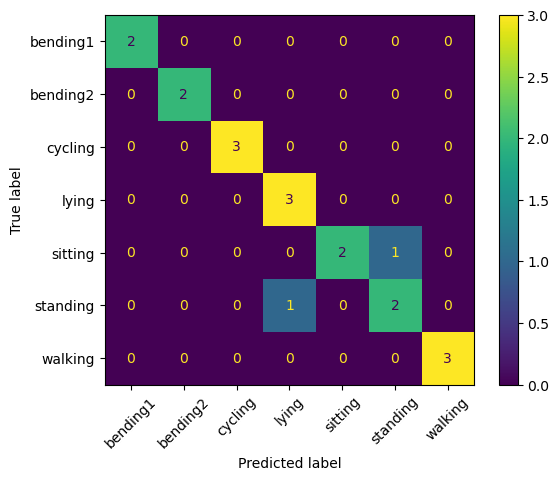

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

best = results7.loc[results7['CV accuracy'].idxmax()]
best_l7 = int(best['l'])
print(f"Best l = {best_l7}, C = {best['best C']:.3f}, CV accuracy = {best['CV accuracy']:.3f}")

X_tr = build_X(best_l7)
X_te = pd.DataFrame([extract_features_l(r['data'], best_l7) for r in records],
                    index=features.index).loc[is_test, X_tr.columns]
model7 = models7[best_l7]
pred7 = model7.predict(X_te.values)
print('Test error:', 1 - accuracy_score(y7_test, pred7))

ConfusionMatrixDisplay.from_predictions(y7_test, pred7, labels=model7.classes_, xticks_rotation=45)
plt.show()

The best l is 1 (no splitting, 18 features) with C = 1.389 and a cross-validation accuracy of 0.898. The accuracy generally decreases for larger l, because 69 training instances are too few to support many features and 7 classes.

The test error is 0.105 (2 of 19 test instances are misclassified): one sitting instance is predicted as standing and one standing instance as lying, while bending1, bending2, cycling, lying and walking are classified perfectly. The confusion matrix is 7 x 7, with the true classes in the rows and the predicted classes in the columns; the diagonal contains the correct predictions and every off-diagonal cell shows which two classes are confused. Sitting, standing and lying are the activities with the least movement, which explains why they are confused with each other.

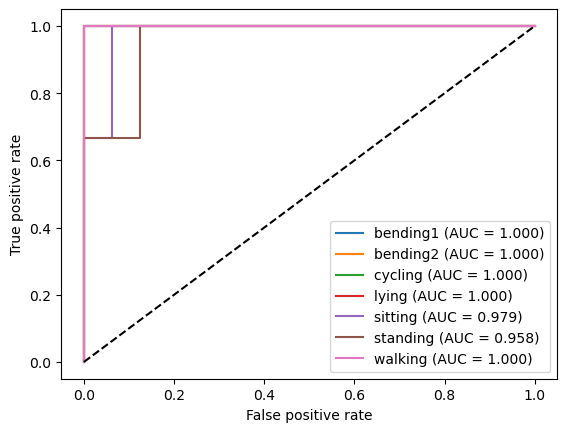

Macro-average one-vs-rest AUC: 0.9910714285714286


In [66]:
from sklearn.preprocessing import label_binarize

proba7 = model7.predict_proba(X_te.values)                      # test instances x 7 class probabilities
Y_bin = label_binarize(y7_test, classes=model7.classes_)        # one 0/1 column per class

for i, c in enumerate(model7.classes_):
    fpr, tpr, _ = roc_curve(Y_bin[:, i], proba7[:, i])
    plt.plot(fpr, tpr, label=f'{c} (AUC = {roc_auc_score(Y_bin[:, i], proba7[:, i]):.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()

print('Macro-average one-vs-rest AUC:',
      roc_auc_score(y7_test, proba7, multi_class='ovr', average='macro'))

For the multiclass ROC curves I use the one-vs-rest definition: for each activity, that activity is the positive class and all other activities are the negative class, scored by the predicted probability of that activity. This gives one ROC curve and one AUC per class. Bending1, bending2, cycling, lying and walking have an AUC of 1.0, and sitting and standing are slightly lower (0.979 and 0.958), consistent with the confusion matrix. The macro-average of the seven AUCs is 0.991. Since each class has only 2 or 3 test instances, the curves are coarse and the AUC values should not be over-interpreted.

## 2(c)ii. Naive Bayes

I repeat 2(c)i with Gaussian and Multinomial Naive Bayes. Neither model has a regularization parameter, so 5-fold stratified cross-validation is only used to choose l. The features are used without standardization, since the Multinomial model requires non-negative features (all mean, standard deviation and maximum features are non-negative).

In [67]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score

nb_rows = []
for l in range(1, 21):
    X = build_X(l)
    nb_rows.append({'l': l,
                    'Gaussian CV accuracy': cross_val_score(GaussianNB(), X.values, y7_train, cv=cv).mean(),
                    'Multinomial CV accuracy': cross_val_score(MultinomialNB(), X.values, y7_train, cv=cv).mean()})

nb_results = pd.DataFrame(nb_rows)
nb_results.round(3)

,l,Gaussian CV accuracy,Multinomial CV accuracy
0,1,0.854,0.825
1,2,0.826,0.841
2,3,0.810,0.841
3,4,0.840,0.841
4,5,0.854,0.825
5,6,0.825,0.811
6,7,0.840,0.842
7,8,0.797,0.842
8,9,0.768,0.827
9,10,0.767,0.811


Gaussian: best l = 1, CV accuracy = 0.854, test error = 0.105


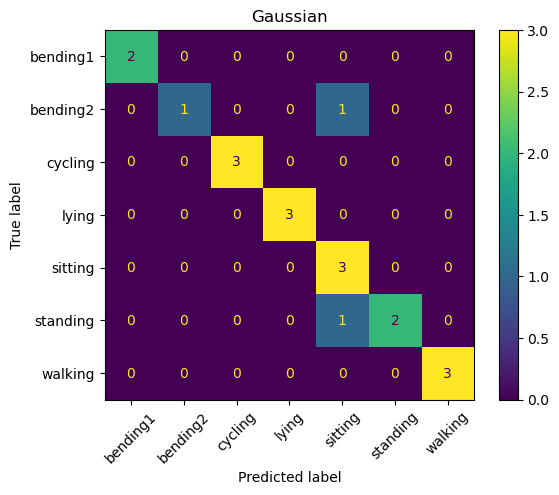

Multinomial: best l = 11, CV accuracy = 0.871, test error = 0.053


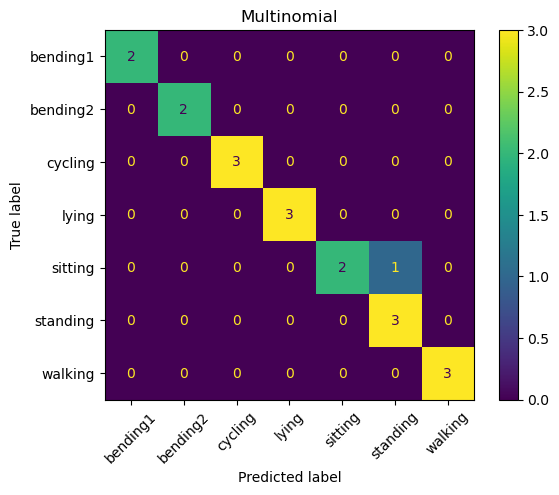

In [68]:
nb_models = {}
for name, col, model in [('Gaussian', 'Gaussian CV accuracy', GaussianNB()),
                         ('Multinomial', 'Multinomial CV accuracy', MultinomialNB())]:
    l_nb = int(nb_results.loc[nb_results[col].idxmax(), 'l'])
    Xtr_nb = build_X(l_nb)
    Xte_nb = pd.DataFrame([extract_features_l(r['data'], l_nb) for r in records],
                          index=features.index).loc[is_test, Xtr_nb.columns]
    model.fit(Xtr_nb.values, y7_train)
    pred_nb = model.predict(Xte_nb.values)
    print(f"{name}: best l = {l_nb}, CV accuracy = {nb_results[col].max():.3f}, "
          f"test error = {1 - accuracy_score(y7_test, pred_nb):.3f}")
    ConfusionMatrixDisplay.from_predictions(y7_test, pred_nb, labels=model.classes_, xticks_rotation=45)
    plt.title(name)
    plt.show()
    nb_models[name] = (model, Xte_nb)        # kept for the ROC curves in the next step

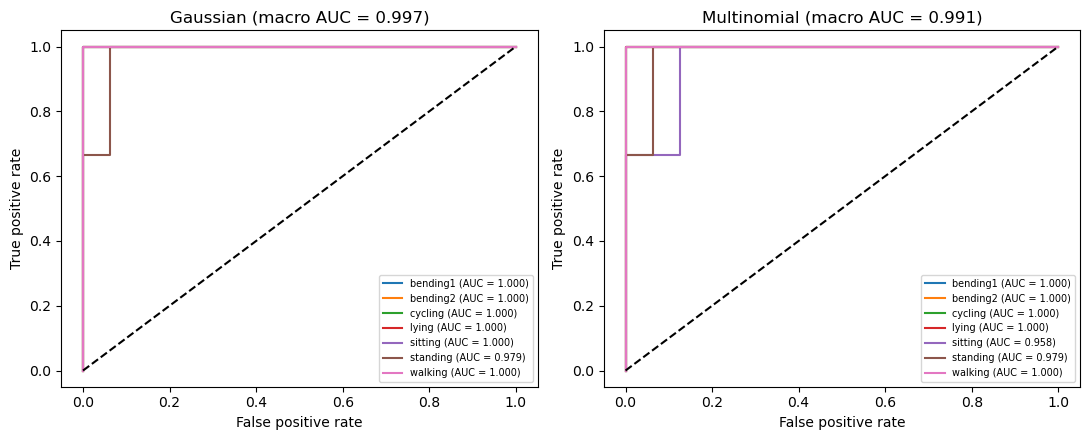

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, (model, Xte_nb)) in zip(axes, nb_models.items()):
    proba_nb = model.predict_proba(Xte_nb.values)
    Y_nb = label_binarize(y7_test, classes=model.classes_)
    for i, c in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(Y_nb[:, i], proba_nb[:, i])
        ax.plot(fpr, tpr, label=f'{c} (AUC = {roc_auc_score(Y_nb[:, i], proba_nb[:, i]):.3f})')
    ax.plot([0, 1], [0, 1], 'k--')
    macro = roc_auc_score(y7_test, proba_nb, multi_class='ovr', average='macro')
    ax.set_title(f'{name} (macro AUC = {macro:.3f})')
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

The best l is 1 for Gaussian Naive Bayes (cross-validation accuracy 0.854, test error 0.105) and 11 for Multinomial Naive Bayes (cross-validation accuracy 0.871, test error 0.053). The Gaussian model misclassifies one bending2 instance as sitting and one standing instance as sitting, while the Multinomial model only misclassifies one sitting instance as standing. Multinomial Naive Bayes is therefore better in both cross-validation accuracy and test error. Its cross-validation accuracy also stays between 0.80 and 0.87 for all l, whereas the accuracy of the Gaussian model decreases from 0.854 at l = 1 to 0.710 at l = 20. The Gaussian model has the higher macro AUC (0.997 vs. 0.991), because its errors are small ranking mistakes (for example, the AUC of bending2 is still 1.0) that only matter for the final arg-max decision.

## 2(c)iii. Comparison for Multiclass Classification

| Method | Best l | CV accuracy | Test error | Macro AUC |
|---|---|---|---|---|
| L1 multinomial logistic regression | 1 | 0.898 | 0.105 | 0.991 |
| Gaussian Naive Bayes | 1 | 0.854 | 0.105 | 0.997 |
| Multinomial Naive Bayes | 11 | 0.871 | 0.053 | 0.991 |

The three methods perform similarly, and no method is clearly the best. The test set has only 19 instances, so the difference between a test error of 0.053 (1 error) and 0.105 (2 errors) is a single instance and is not reliable. The cross-validation accuracy uses all 69 training instances and is more reliable: it ranks L1-penalized multinomial logistic regression first (0.898), followed by Multinomial Naive Bayes (0.871) and Gaussian Naive Bayes (0.854). I therefore consider the L1-penalized multinomial logistic regression slightly better: it has the highest cross-validation accuracy, it reaches it with l = 1 (only 18 features), and it does not assume that the features are independent. Multinomial Naive Bayes has the lowest test error, so it is a close second. All three methods confuse only sitting, standing, lying and (for the Gaussian model) bending2, and have a macro AUC of at least 0.99.

## 3. ISLR 4.8.3


The Bayes classifier assigns $x$ to the class $k$ that maximizes $\pi_k f_k(x)$, where $f_k(x) = \frac{1}{\sqrt{2\pi}\sigma_k}e^{-(x-\mu_k)^2/(2\sigma_k^2)}$. Taking logs and dropping terms that do not depend on $k$, it maximizes
$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k x}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k .$$
This is a quadratic function of $x$, and the coefficient of $x^2$, $-1/(2\sigma_k^2)$, depends on $k$. Since the variances differ across classes, the $x^2$ term does not cancel when the classes are compared (it would cancel if $\sigma_1^2 = \dots = \sigma_K^2$, giving the linear LDA). Hence the Bayes classifier is quadratic, not linear.

## 4. ISLR 4.8.7

**Setup.** Let $Y \in \{\text{Yes}, \text{No}\}$ indicate whether a company issued a dividend, and $X$ be last year's percent profit. In each class $X$ is normal with a common variance:
$$X \mid Y=\text{Yes} \sim N(10, 36), \qquad X \mid Y=\text{No} \sim N(0, 36),$$
with prior probabilities $\pi_{\text{Yes}} = 0.8$ and $\pi_{\text{No}} = 0.2$.

**Bayes' theorem.** With the normal density $f(x) = \frac{1}{\sqrt{2\pi\sigma^2}}e^{-(x-\mu)^2/(2\sigma^2)}$,
$$\Pr(Y=\text{Yes} \mid X=4) = \frac{\pi_{\text{Yes}}\, f_{\text{Yes}}(4)}{\pi_{\text{Yes}}\, f_{\text{Yes}}(4) + \pi_{\text{No}}\, f_{\text{No}}(4)}.$$
Both densities have the same variance, so the factor $1/\sqrt{2\pi\sigma^2}$ cancels, and
$$\Pr(Y=\text{Yes} \mid X=4) = \frac{0.8\, e^{-(4-10)^2/(2\cdot 36)}}{0.8\, e^{-(4-10)^2/(2\cdot 36)} + 0.2\, e^{-(4-0)^2/(2\cdot 36)}} = \frac{0.8\, e^{-1/2}}{0.8\, e^{-1/2} + 0.2\, e^{-2/9}} \approx \frac{0.4852}{0.4852 + 0.1601} \approx 0.752 .$$

**Answer.** The predicted probability that the company issues a dividend this year, given a percent profit of $X = 4$ last year, is approximately **0.752** (75.2%).